# Uczenie maszynowe i sieci neuronowe

### Ćwiczenia 2.

---

## Regresja logistyczna

Tematem tych ćwiczeń jest regresja logistyczna. Napiszemy od podstaw model rozwiązujący zadanie klasyfikacji binarnej oparty na metodzie regresji logistycznej, a następnie postaramy się jak najlepiej go wytrenować.

---

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import preprocessing
from testing import *
from import_data import load_data_split, load_data
import sympy as sp

[Moduł `testing`](testing.py) zawiera przygotowane na potrzeby tych ćwiczeń narzędzia do testowania poprawności kodu źródłowego.

---

### Dane: *Pima Indians Diabetes Database*

W ramach dzisiejszych ćwiczeń wykorzystamy zbiór danych [*Pima Indians Diabetes Database*](diabetes.csv), opracowany na podstawie badań prowadzonych przez amerykański Narodowy Instytut Cukrzycy oraz Chorób Układu Pokarmowego i Nerek (ang. *National Institute of Diabetes and Digestive and Kidney Diseases*). Zbiór ten służy przede wszystkim do budowania modeli klasyfikacji binarnej, których celem jest przewidzenie na podstawie określonych wskaźników medycznych, czy pacjent zachoruje na cukrzycę typu 2 w ciągu 5 lat od badania.

Dane zawarte w zbiorze dotyczą kobiet w wieku co najmniej 21 lat, pochodzących z plemienia Indian Pima, zamieszkującego okolice rzeki Gila w stanie Arizona w Stanach Zjednoczonych. Populacja ta genetycznie i środowiskowo wykazuje wyjątkowo wysoką podatność na otyłość oraz cukrzycę typu 2.

**Struktura danych**

Liczba obserwacji: **768**.

Liczba zmiennych: **9** – 8 cech i 1 etykieta.

Cechy (8).
1. Pregnancies (Ciąże): Liczba przebytych ciąż.
2. Glucose (Glukoza): Stężenie glukozy w osoczu po 2 godzinach w doustnym teście tolerancji glukozy (OGTT).
3. BloodPressure (Ciśnienie krwi): Rozkurczowe ciśnienie krwi (mm Hg).
4. SkinThickness (Grubość skóry): Grubość fałdu skórnego nad mięśniem trójgłowym ramienia (mm) – stosowana jako miara tkanki tłuszczowej.
5. Insulin (Insulina): Poziom insuliny w surowicy po 2 godzinach od podania glukozy (mu U/ml).
6. BMI (Wskaźnik masy ciała): Wskaźnik masy ciała (waga w kg / (wzrost w m)²).
7. DiabetesPedigreeFunction (Funkcja rodowodu cukrzycy): Funkcja obliczająca prawdopodobieństwo wystąpienia cukrzycy na podstawie historii medycznej rodziny (genetyki).
8. Age (Wiek): Wiek pacjentki (wszystkie kobiety w zbiorze mają co najmniej 21 lat).

Etykieta: Outcome, przyjmuje następujące wartości:
* 1 – wynik pozytywny: cukrzyca została zdiagnozowana w ciągu 5 lat od badania – 268 przypadków,
* 0 – wynik negatywny: cukrzyca nie została zdiagnozowana w ciągu 5 lat od badania – 500 przypadków.

**Wyzwania**

Praca ze zbiorem *Pima Indians Diabetes Database* wymaga pewnej ostrożności z następujących powodów:
* **braki danych** – wiele kolumn zawiera brakujące dane, reprezentowane przez wartości równe 0; przed trenowaniem modelu należy je zastąpić (np. medianą lub średnią),
* **niezbalansowanie klas** – w zbiorze występuje więcej przypadków negatywnych niż pozytywnych; może to powodować, że prosty model będzie chętniej klasyfikował pacjentów jako zdrowych.

<hr style="width: 50%; margin-inline: auto;" />

Zanim zaczniemy pracę przyjrzyjmy się danym, z którymi będziemy pracować.

Na początku wczytamy dane na dwa sposoby: z podziałem na dane treningowe i testowe oraz jako ramkę danych biblioteki Pandas.

In [2]:
data_train, data_test = load_data_split("diabetes.csv")

df = pd.read_csv("diabetes.csv")

Popatrzmy na pierwsze dziesięć wierszy zbioru danych.

In [3]:
df.head(10)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
5,5,116,74,0,0,25.6,0.201,30,0
6,3,78,50,32,88,31.0,0.248,26,1
7,10,115,0,0,0,35.3,0.134,29,0
8,2,197,70,45,543,30.5,0.158,53,1
9,8,125,96,0,0,0.0,0.232,54,1


Narysujemy histogramy wybranych wielkości.

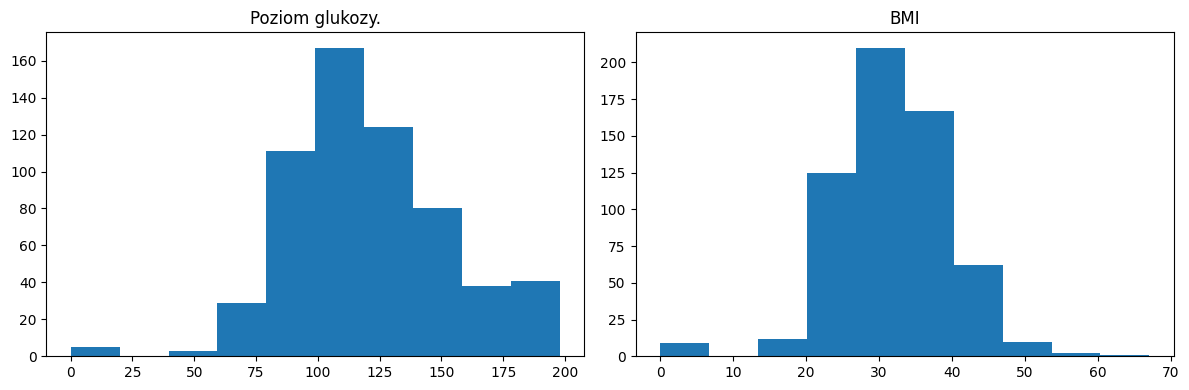

In [4]:
fig_size = [12, 4]
plt.rcParams["figure.figsize"] = fig_size

plt.subplot(1, 2, 1)
plt.hist(data_train["Xi"][1])
plt.title(r'Poziom glukozy.')

plt.subplot(1, 2, 2)
plt.hist(data_train["Xi"][5])
plt.title(r'BMI')

plt.tight_layout()
plt.show()

Spróbujemy teraz przyjrzeć się wpływowi dwóch wskaźników, BMI i ciśnienia krwi, na ryzyko zachorowania na cukrzycę.

In [5]:
col_list = ["BMI","BloodPressure", "Outcome"]
df = pd.read_csv("diabetes.csv", usecols=col_list)

df['strikebins'] = pd.cut(df['BMI'], bins=6)
grouped = df.groupby(['strikebins'])
new_df = grouped[["BMI","BloodPressure", "Outcome"]].mean().drop(0)
new_df["Outcome"] = new_df["Outcome"]*100

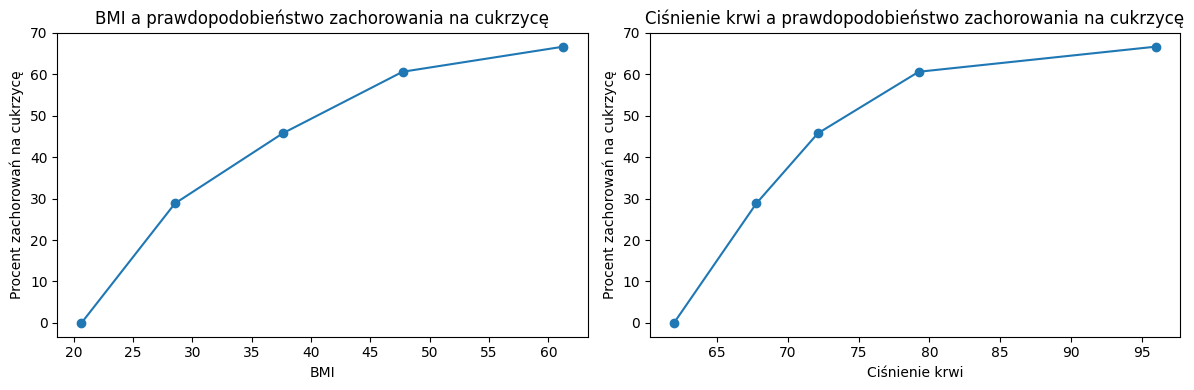

In [6]:
fig_size = [12, 4]
plt.rcParams["figure.figsize"] = fig_size

plt.subplot(1, 2, 1)
plt.plot(new_df["BMI"], new_df["Outcome"])
plt.scatter(new_df["BMI"], new_df["Outcome"])
plt.title(r'BMI a prawdopodobieństwo zachorowania na cukrzycę')
plt.ylabel('Procent zachorowań na cukrzycę')
plt.xlabel('BMI')

plt.subplot(1, 2, 2)
plt.plot(new_df["BloodPressure"],new_df["Outcome"])
plt.scatter(new_df["BloodPressure"],new_df["Outcome"])
plt.title(r'Ciśnienie krwi a prawdopodobieństwo zachorowania na cukrzycę')
plt.ylabel('Procent zachorowań na cukrzycę')
plt.xlabel('Ciśnienie krwi')
plt.tight_layout()
plt.show()

---

### Regresja logistyczna w klasyfikacji binarnej

**Klasyfikacja binarna** to zadanie uczenia maszynowego polegające na przypisaniu danych wejściowych do jednej z dwóch wzajemnie wykluczających się klas (np. TAK / NIE, spam / nie-spam, chory / zdrowy). Jedną z klas oznacza się zazwyczaj jako pozytywną i przypisuje jej cyfrę 1 (np. wykrycie oszustwa lub choroby), a drugą jako negatywną z przypisaną cyfrą 0 (np. brak oszustwa lub choroby). Model zwraca decyzję dyskretną (0 lub 1) lub prawdopodobieństwo przynależności do klasy pozytywnej.

**Regresja logistyczna** to metoda statystyczna pozwalająca rozwiązać zadanie klasyfikacji binarnej (istnieją też inne sposoby rozwiązywania tego zadania). Omówimy teraz dokładnie ten algorym.

Rozważmy zbiór danych $(X^{(i)}, Y^{(i)})_{i=1}^N$. Naszym celem jest wyznaczenie przewidywanej wartości $\hat{Y} \in {0,1}$. 

W każdej iteracji algorytmu regresji logistycznej wykonujemy następujące kroki.
1. **Propagacja w przód**:
  * oblicz
    $$
    Z_1 = W*X+b,
    $$
  * oblicz
    $$
    A_1 = \sigma \left( Z_1 \right) ,
    $$
    gdzie $\sigma = \sigma (z)$ to **funkcja logistyczna**, w kontekście uczenia maszynowego określana też jako **funkcja sigmoidalna** lub **sigmoid**, dana wzorem
    $$
    \sigma (z) = \frac{1}{1 + e^{-z}}, 
    $$
  * oblicz funkcję kosztu
    $$
    J(W, \, b) = -\frac{1}{N}\sum_{i=1}^N \left( Y^{(i)} \log A_1^{(i)} + (1-Y^{(i)}) \log \left(1-A_1^{(i)}\right)\right) ,
    $$
    przy czym $\log z$ oznacza tu logarytm naturalny (inne oznaczenie to $\ln z$),
  * oblicz pochodne cząstkowe funkcji kosztu:
    $$
    \begin{aligned}
    \frac{\partial J(W,b)}{\partial W_j}&=\frac{1}{N} \sum_{i=1}^N \left(A_1^{(i)} - Y^{(i)}\right)X^{(i)}_j,\\[3pt]
    \frac{\partial J(W,b)}{\partial b}&=\frac{1}{N} \sum_{i=1}^N \left(A_1^{(i)} - Y^{(i)}\right)
    \end{aligned}
    $$
    (wyprowadzając te wzory wygodnie jest skorzystać z tego, że $\sigma'(z) = \sigma(z)(1 - \sigma(z))$ oraz $\log ' z = \frac{1}{z}$).
2. **Propagacja w tył** - wykonaj jeden krok metody gradientu prostego:
   $$
   \begin{aligned}
   W_{n+1}&=W_{n} - \alpha \frac{\partial J(w_{n},b_{n})}{\partial W},\\[3pt]
   b_{n+1}&= b_{n} - \alpha \frac{\partial J(w_{n},b_{n})}{\partial b}.
   \end{aligned}
   $$

---

### Zadanie 1. Inicjalizacja.

Napisz funkcję `initialization`, której zadaniem jest zwrócenie początkowych wartości $W$ i $b$.  Wartości te powinny być losowane z rozkładu normalnego Gaussa o parametrach zadanych jako argumenty funkcji. Pamiętaj, że $W$ jest wektorem o długości równej liczbie zmiennych zależnych, czyli macierzą wymiaru `(liczba zmiennych zależnych, 1)`, zaś $b$ jest liczbą.

_Wskazówka._ Może Ci się przydać funkcja [random.randn](https://numpy.org/doc/stable/reference/random/generated/numpy.random.randn.html) z biblioteki NumPy.

In [21]:
def initialization(dim, sigma1, sigma2, mu1=0, mu2=0):
    """
    Funkcja inicjalizująca parametry W i b z rozkładu normalnego Gaussa.
    :param dim: int, wymiar W oraz danych wczytywanych do programu.
    :param sigma1: float >= 0, odchylenie standardowe rozkładu normalnego, z którego losowane jest W.
    :param sigma2: float >= 0, odchylenie standardowe rozkładu normalnego, z którego losowane jest b.
    :param mu1: float, średnia rozkładu normalnego, z którego losowane jest W. Domyślnie mu1 = 0.
    :param mu2: float, średnia rozkładu normalnego, z którego losowane jest b. Domyślnie mu2 = 0.

    :return: array o rozmiarze (dim, 1) W oraz float b. W i b są losowane z rozkładów normalnych.
    """

    ### Miejsce na Twój kod ############################################
    W = np.random.normal(mu1, sigma1,(dim,1))
    b = np.random.normal(mu2, sigma2)
    return W, b
    ### Koniec miejsca na Twój kod #####################################

Wykonaj poniższą komórkę, aby sprawdzić, czy Twój kod działa poprawnie.

In [25]:
try:
    A,b = initialization(dim_test, 1, 2)
    assert(A.shape == (dim_test,1))
    assert(type(b) is float or type(b) is int)

    n_test, sigma1, sigma2, mu1, mu2 =(10000,1, 2, 1, 2)
    lst1 = [initialization(1, sigma1, sigma2, mu1, mu2)[0] for _ in range (1,n_test,1)]
    lst2 = [initialization(1, sigma1, sigma2, mu1, mu2)[1] for _ in range (1,n_test,1)]
    assert(sigma_check(lst1,mu1,sigma1)<0.01)
    assert(sigma_check(lst2,mu2,sigma2)<0.01)
    print("Gratulacje, Twój kod działa poprawnie! :)")
except AssertionError:
    print("Twój kod nie działa poprawnie, spróbuj ponownie. :(")

Gratulacje, Twój kod działa poprawnie! :)


---

### Zadanie 2. Sigmoid.

Korzystając z podanego wyżej wzoru napisz funkcję `sigmoid` stanowiącą implementację funkcji logistycznej. Funkcja `sigmoid` powinna przyjmować argument $z$ i zwracać wartość $\sigma (z)$.

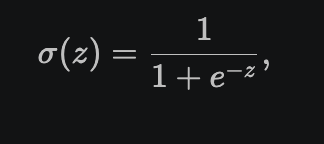

In [26]:
def sigmoid(z):
    """
    Funkcja logistyczna.

    :param z: float lub np.array, argument funkcji.

    :return: float lub np.array (taki sam kształt jak z), wartość sigmoid(z).
    """

    jestem_sigma = 1/(1+np.exp(-z))

    

    ### Miejsce na Twój kod ############################################
    return jestem_sigma
    ### Koniec miejsca na Twój kod #####################################

Wykonaj poniższą komórkę, aby sprawdzić, czy Twój kod działa poprawnie.

In [27]:
try:
    assert(abs(sigmoid(0)-1/2)<eps_test)
    assert((sigmoid(1)-1/2)>eps_test)
    assert((sigmoid(-1)-1/2)<eps_test)
    print("Gratulacje, Twój kod działa poprawnie! :)")
except AssertionError:
    print("Twój kod nie działa poprawnie, spróbuj ponownie. :(")

Gratulacje, Twój kod działa poprawnie! :)


---

### Zadanie 3. Propagacja w przód.

Napisz funkcję `propagate` wykonującą propagację w przód, czyli pierwszy krok podanego wyżej algorytmu regresji logistycznej.

_Wskazówka._ Mogą Ci się przydać metoda [np.dtype](https://numpy.org/doc/stable/reference/arrays.dtypes.html) oraz funkcje [shape](https://numpy.org/doc/stable/reference/generated/numpy.shape.html) i [squeeze](https://numpy.org/doc/stable/reference/generated/numpy.squeeze.html) z biblioteki NumPy.

In [43]:
def propagate(W, b, Xi, Yi):
    """
    Funkcja zwracająca gradienty i koszt regresji logistycznej dla zestawu danych. Funkcja powinna sprawdzać, czy dane Xi oraz Yi mają tę samą liczbę próbek oraz czy liczba próbek jest większa niż 1.

    :param W: np.array o rozmiarze (dim, 1), wagi (nachylenie).
    :param b: float, parametr wolny (bias).
    :param Xi: np.array o rozmiarze (liczba zmiennych niezależnych, liczba danych), dane wejściowe.
    :param Yi: np.array o rozmiarze (1, liczba danych), etykiety (0 lub 1).

    :return: słownik grad z podchodnymi cząstkowymi dW (np.array, rozmiar taki sam jak W) i db (float), float cost (koszt).
    """

    ### Miejsce na Twój kod ############################################
    
    NXi = Xi.shape[1] # Ile jest próbek? Użyj funkcji shape.
    NyY = Yi.shape[1] 

    assert (NXi == NyY and NXi > 1), "Dane nie mają tej samej liczby próbek lub liczba próbek jest mniejsza niż 1."
    
    Z1 = np.dot(W.T,Xi) + b
    A1 = sigmoid(Z1)

    cost = -1/NXi*np.sum(Yi*np.log(A1) + (1-Yi)*np.log(1-A1)) # Wartość funkcji kosztu.
    # Upewnij się, że koszt jest typu float, a nie np.array. Możesz użyć funkcji squeeze.
    cost = float(np.squeeze(cost))
    # Pochodne cząstkowe funkcji kosztu względem W i b

    dZ = A1 - Yi

    dW = np.dot(Xi,dZ.T) / NXi
    db = np.sum(dZ) / NXi
                
    # Upewnij się, że dW ma taki sam kształt jak W, a db jest typu float.

    assert(dW.shape == W.shape)
    assert(isinstance(db, (int, float)))



    grad = {
        "dW": dW,
        "db": db
    }

    return grad, cost
    ### Koniec miejsca na Twój kod #####################################

Wykonaj poniższą komórkę, aby sprawdzić, czy Twój kod działa poprawnie.

In [45]:
try:
    A_test, b_test, X_test, Y_test = np.array([[1.],[1.5]]), 1., np.array([[1.,2.,-1.],[3.,4.,-3.2]]), np.array([[1,0,1]])
    data_testing = {"Xi":X_test,"Yi":Y_test}
    grads, cost = propagate(A_test, b_test, X_test,Y_test)
    assert(sum(abs(np.array(grads["dW"]) -grads_test["dW"]))<eps_test2)
    assert((abs(grads["db"]) - grads_test["db"])<eps_test)
    assert(abs(cost - cost_test)<eps_test)
    print("Gratulacje, Twój kod działa poprawnie! :)")
except AssertionError:
    print("Twój kod nie działa poprawnie, spróbuj ponownie. :(")

Gratulacje, Twój kod działa poprawnie! :)


---

### Zadanie 4. Optymalizacja, czyli trening modelu.

Napisz funkcję `optimize`, która wielokrotnie, w pętli, będzie wykonywać opisany powyżej algorytm regresji logistycznej (tzn. progagację w przód i propagację w tył). Wykorzystaj funkcje napisane w poprzednich zadaniach.

Funkcja `optimize` powinna co 1000 kroków wypisywać wartość funkcji kosztu.

In [46]:
def optimize(W, b, Xi, Yi, num_iterations, learning_rate, print_cost = False):

    """
    Funkcja optymalizująca parametry W i b metodą spadku gradientu (gradienty i koszt liczone funkcją propagate).
    :param W: np.array o rozmiarze (dim, 1), wagi.
    :param b: float, parametr wolny (bias).
    :param Xi: np.array o rozmiarze (liczba zmiennych niezależnych, liczba danych), dane wejściowe.
    :param Yi: np.array o rozmiarze (1, liczba danych), etykiety (0 lub 1).
    :param num_iterations: int, liczba iteracji uczenia.
    :param learning_rate: float, współczynnik uczenia (hiperparametr).
    :param print_cost: bool, domyślnie False. Jeśli True, koszt jest wypisywany co 1000 iteracji.

    :return: dict params ze zoptymalizowanymi W (np.array) i b (float), dict grads z gradientami z ostatniej iteracji, list costs z kosztami zapisywanymi co 1000 iteracji.
    """

    ### Miejsce na Twój kod ############################################
    costs = []

    for i in range(num_iterations):

        # Liczenie gradientu i kosztu (funkcja propagate).
        grad, cost = propagate(W, b, Xi, Yi)

        # Pochodne cząstkowe (słownik grad).
        dW = grad["dW"]
        db = grad["db"]

        # Jeden krok metody gradientu prostego (aktualizacja parametrów W i b).
        W = W - learning_rate * dW
        b = b - learning_rate * db

        # Zapisujemy koszt co 1000 kroków
        if i % 1000 == 0:
            costs.append(cost)

        # Wypisujemy koszt co 1000 krokow
        if print_cost and i % 1000 == 0:
            print(f"Koszt po iteracji {i}: {cost}")

    params = {"W": W,
              "b": b}

    grad = {"dW": dW,
             "db": db}

    return params, grad, costs
    ### Koniec miejsca na Twój kod #####################################

Wykonaj poniższą komórkę, aby sprawdzić, czy Twój kod działa poprawnie.

In [47]:
try:
    w, b, X, Y = np.array([[1.],[2.]]), 2., np.array([[1.,2.,-1.],[3.,4.,-3.2]]), np.array([[1,0,1]])
    params, grads, costs = optimize(w, b, data_testing["Xi"],data_testing["Yi"], num_iterations= 10000, learning_rate = 0.009, print_cost = False)
    assert(abs(sum(params["W"]))<10)
    assert(abs(params["b"])<10)
    assert(abs(sum(grads["dW"]))<1e-1)
    assert(abs(grads["db"])<1e-1)
    print("Gratulacje, Twój kod działa poprawnie! :)")
except AssertionError:
    print("Twój kod nie działa poprawnie, spróbuj ponownie. :(")

Gratulacje, Twój kod działa poprawnie! :)


---

### Zadanie 5. Przywidywania.

Napisz funkcję `predict`, która zwraca przewidywania modelu. Gdy $A_1\geq 1/2$, przewidywana klasa to $\hat{Y}=1$, jeśli zaś $A_1<1/2$, przewidywaną klasą jest $\hat{Y}=0$.

*Wskazówka*. Wykorzystaj *boolean mask*.

In [50]:
def predict(W, b, X):
    """
    Funkcja przewidująca, czy wynik klasyfikacji to jeden czy zero.
    :param W: np.array o rozmiarze (dim, 1), wagi.
    :param b: float, parametr wolny (bias).
    :param X: np.array o rozmiarze (liczba zmiennych niezależnych, liczba danych), zbiór danych do klasyfikacji.

    :return: np.array o rozmiarze (1, liczba danych), przewidywana klasa (0 lub 1) dla każdej próbki ze zbioru X.
    """

    ### Miejsce na Twój kod ############################################

    N = X.shape[1]

    # Oblicz A1.
    A1 = sigmoid(np.dot(W.T, X) + b)

    # Przelicz wartość A1 na predykcję modelu (0 lub 1).
    bool_pred = A1 > 0.5
    pred = bool_pred.astype(int)

    return pred.flatten()
    ### Koniec miejsca na Twój kod #####################################

Wykonaj poniższą komórkę, aby sprawdzić, czy Twój kod działa poprawnie.

In [51]:
try:
    w_predict_test = np.array([[0.8173],[0.23106775]])
    b_predict_test =-0
    X_predict_test = np.array([[1.,-1.1,-3.2],[1.2,2.,0.1]])
    pred_test = predict(w_predict_test,b_predict_test,X_predict_test)
    assert(len(pred_test)==X_predict_test.shape[1])
    assert(sum(pred_test-np.array([1,0,0]))<eps_test)
    print("Gratulacje, Twój kod działa poprawnie! :)")
except AssertionError:
    print("Twój kod nie działa poprawnie, spróbuj ponownie. :(")

Gratulacje, Twój kod działa poprawnie! :)


---

### Testowanie modelu

Wykorzystując funkcje napisane w poprzednich zadaniach możemy już zbudować nasz model klasyfikacji binarnej.

In [52]:
def model(data_train, data_test, num_iterations=1000, learning_rate=0.05, print_cost=False):
    """
    Funkcja wykonująca regresję logistyczną: trenuje model i liczy jego dokładność na danych treningowych i testowych.
    :param data_train: dict z kluczami "Xi" i "Yi", zbiór danych treningowych.
    :param data_test: dict z kluczami "Xi" i "Yi", zbiór danych testowych.
    :param num_iterations: int, liczba iteracji uczenia. Domyślnie 1000.
    :param learning_rate: float, współczynnik uczenia (hiperparametr). Domyślnie 0.05.
    :param print_cost: bool, domyślnie False. Jeśli True, koszt jest wypisywany co 1000 iteracji.

    :return: dict z kluczami: costs (koszty), Y_prediction_test, Y_prediction_train (przewidywania), A (nauczone wagi W), b, learning_rate, num_iterations.
    """

    #Preprocessing danych
    x_test = preprocessing.normalize(data_test["Xi"])
    x_train = preprocessing.normalize(data_train["Xi"])
    y_test = data_test["Yi"]
    y_train = data_train["Yi"]

    # Inicjalizacja parametrów
    WW, bb = initialization((x_train.shape[0]),0.1,0.1,1)
    
    #Trenowanie modelu
    parameters, _, costs = optimize(WW, bb, x_train, y_train, num_iterations, learning_rate, print_cost)

    W = parameters["W"]
    b = parameters["b"]

    # Przewidywania modelu na zbiorach danych testowych i treningowych
    y_prediction_test = predict(W, b, x_test)
    y_prediction_train = predict(W, b, x_train)

    # Print train/test Errors
    print("Dokladnosc dla danych treningowych: {} %".format(100 - np.mean(np.abs(y_prediction_train - y_train)) * 100))
    print("Dokladnosc danych testowych: {} %".format(100 - np.mean(np.abs(y_prediction_test - y_test)) * 100))


    wynik = {"costs": costs,
         "Y_prediction_test": y_prediction_test,
         "Y_prediction_train" : y_prediction_train,
         "A" : W,
         "b" : b,
         "learning_rate" : learning_rate,
         "num_iterations": num_iterations}

    return wynik

Przetestujmy nasz model. Pobaw się wartościami parametrów (liczbą iteracji i *learning rate*). Spróbuj osiągnąć dokładność większą niż 80%.

In [81]:
wynik = model(data_train, data_test, num_iterations = 10000, learning_rate = 0.01
              , print_cost = True)

Koszt po iteracji 0: 0.7077112196416769
Koszt po iteracji 1000: 0.633732811802984
Koszt po iteracji 2000: 0.632901414276992
Koszt po iteracji 3000: 0.6326763483772468
Koszt po iteracji 4000: 0.6324581636165075
Koszt po iteracji 5000: 0.6322408325212627
Koszt po iteracji 6000: 0.6320242894460755
Koszt po iteracji 7000: 0.631808530142265
Koszt po iteracji 8000: 0.6315935510074607
Koszt po iteracji 9000: 0.6313793484598877
Dokladnosc dla danych treningowych: 65.38461538461539 %
Dokladnosc danych testowych: 76.76767676767676 %


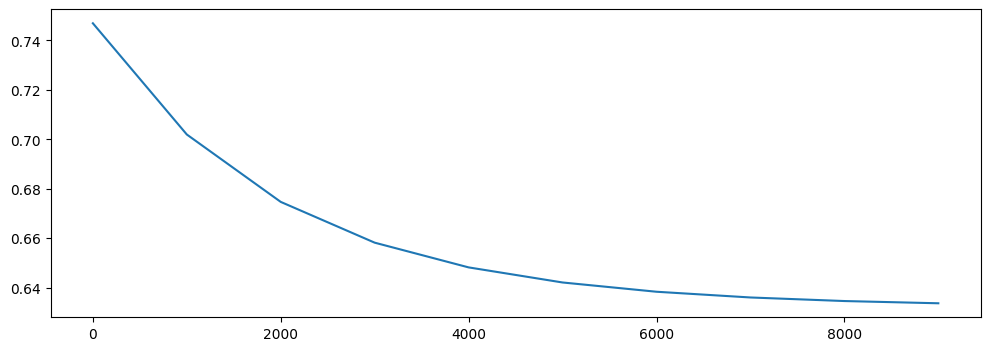

In [80]:
plt.plot(list(range(0,len(wynik["costs"])*1000,1000)),wynik["costs"])

---

### Zadanie dodatkowe. Bank. 

Wykonaj zadanie klasyfikacji binarnej na innym zbiorze danych.

In [ ]:
data_pandas = pd.read_csv("train_data.csv")
data_pandas.head(20)

In [ ]:
labels, data_train = load_data("train_data.csv", 2, 24000)
_, data_test = load_data( "train_data.csv", 24001, 30000)

In [ ]:
# Miejsce na Twoje rozwiązanie